### Finding the Cumulative Tip Coverage of Future Sequences Versus Minimum Mutation Distance

In this notebook, we analyze how well current spike sequences capture future ones by measuring cumulative tip coverage across defined future intervals. 

The analysis quantifies coverage as a function of the minimum mutation distance between present and future sequences, providing insight into the evolutionary proximity of predicted variants.



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    with open(file_path, 'rb') as file:
        return pickle.load(file)

In [ ]:
# --- Load data files ---
ROOT_PATH = "/data/sukhanna/MPP/"
PARENT_PATH = ROOT_PATH +"ver_2/ver_2A/new_MAT/"
DATA_PATH = PARENT_PATH +"final_df.parquet"

final_df = pd.read_parquet(DATA_PATH)

id_to_seq = load_data(PARENT_PATH + "sequence_dict.pkl")

refSeq = getReference(ROOT_PATH + 'cov_reference.fa')

Create Disjoint time interval slices

In [4]:
# --- Define cutoff date ---
cutoff_date = "2022-07-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']

# --- Perform slicing ---
disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Combine slices into one dictionary ---
future_slices = disjoint_slices

# --- Summary output ---
# print(f"Cumulative slices: {list(cumulative_slices.keys())}")
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['3M_1', '3M_2', '3M_3', '3M_4']
Total future slices stored: 4


In [5]:
# --- Compute tip counts for current circulating sequences ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

# --- Compute tip counts for each future window ---
future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

# --- Summary output ---
print(f"Computed current sequence DataFrame with {len(current_seq_df)} unique sequences")
print(f"Computed future sequence DataFrames for {len(future_seq_dfs)} windows")

Computed current sequence DataFrame with 17477 unique sequences
Computed future sequence DataFrames for 4 windows


### Loading Precomputed distance results
We precompute a csv file which provides a map of the future sequence and their minimum distance from the current sequence database.

You can supply a csv file or use the code in temp_folder_name for the same

In [6]:
import os
from glob import glob

# --- Directory containing the future distance CSVs ---
data_dir = "/data/sukhanna/MPP/ver_2/ver_2A/new_MAT/Disjoint_30D/2022-07-01"

# --- Retrieve all CSV files matching the pattern "dist_*.csv" ---
csv_files = glob(os.path.join(data_dir, "dist_*.csv"))

# --- Dictionary to store DataFrames for each future interval ---
future_dist_dfs = {}

# --- Column names for CSVs (no header in files) ---
columns = ["Future_Sequence_ID", "Current_Sequence_ID", "Minimum_Distance"]

# --- Read each CSV and store in dictionary keyed by interval ---
for file in csv_files:
    key = os.path.basename(file).replace("dist_", "").replace(".csv", "")
    
    df = pd.read_csv(file, header=None, names=columns)
    
    future_dist_dfs[key] = df

# --- Summary output ---
print(f"Loaded {len(future_dist_dfs)} future distance DataFrames")
for key, df in future_dist_dfs.items():
    print(f" - {key}: {len(df)} rows")

Loaded 4 future distance DataFrames
 - 3M_1: 37199 rows
 - 3M_3: 38172 rows
 - 3M_2: 41675 rows
 - 3M_4: 25954 rows


### Computing all the results and compiling in cumulative form

In [7]:
# --- Dictionary to store cumulative coverage results for each future interval ---
results = {}

# --- Compute cumulative tip coverage by minimum mutation distance for each future window ---
for key in future_dist_dfs.keys():
    # DataFrame of distances for the current future window
    dist_df = future_dist_dfs[key]
    
    # DataFrame of tip counts for the same future window
    seq_df = future_seq_dfs[key]

    # --- Merge distance data with tip counts for future sequences ---
    merged = dist_df.merge(
        seq_df,
        left_on="Future_Sequence_ID",
        right_on="Sequence_ID"
    )

    # --- Aggregate tip counts by minimum mutation distance ---
    dist_counts = (
        merged.groupby("Minimum_Distance")["Tip_Count"]
        .sum()
        .reset_index()
        .sort_values("Minimum_Distance")
    )

    # --- Compute cumulative percentage of tips covered ---
    total = dist_counts["Tip_Count"].sum()
    dist_counts["Cumulative_%"] = dist_counts["Tip_Count"].cumsum() / total

    # --- Store only relevant columns in results dictionary ---
    results[key] = dist_counts[["Minimum_Distance", "Cumulative_%"]]

# --- Summary output ---
print(f"Computed cumulative tip coverage for {len(results)} future windows")
for key in results.keys():
    print(f" - {key}: {len(results[key])} distance bins")


Computed cumulative tip coverage for 4 future windows
 - 3M_1: 18 distance bins
 - 3M_3: 21 distance bins
 - 3M_2: 22 distance bins
 - 3M_4: 23 distance bins


### Plotting Cumulativer Results

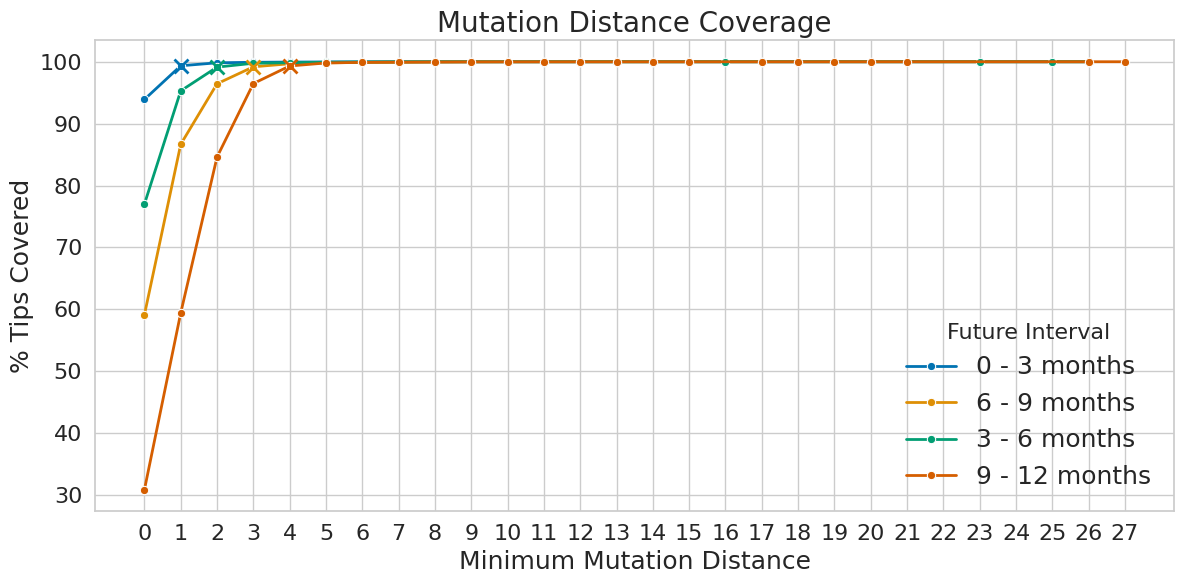

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Threshold for marking where cumulative coverage reaches 99% ---
threshold = 0.99  # stored as 0–1, convert to % later

# --- Mapping for nicer interval labels in the legend ---
legend_labels = {
    "3M_1": "0 - 3 months",
    "3M_2": "3 - 6 months",
    "3M_3": "6 - 9 months",
    "3M_4": "9 - 12 months"
}

# --- Prepare data for plotting ---
plot_data = []
marker_points = {}  # store x,y for first threshold exceed per slice
max_dist = 0        # track max distance for x-axis

for key, df in results.items():
    max_dist = max(max_dist, df["Minimum_Distance"].max())
    first_marker_set = False
    
    for _, row in df.iterrows():
        # --- Append row for plotting ---
        plot_data.append({
            "Distance": row["Minimum_Distance"],
            "Slice": legend_labels.get(key, key),
            "Cumulative %": row["Cumulative_%"] * 100  # convert fraction to %
        })
        
        # --- Record first point where threshold is exceeded ---
        if not first_marker_set and row["Cumulative_%"] >= threshold:
            marker_points[key] = (row["Minimum_Distance"], row["Cumulative_%"] * 100)
            first_marker_set = True

df_plot = pd.DataFrame(plot_data)

# --- Ensure all distances appear on x-axis ---
full_counts = list(range(0, max_dist + 1))
df_plot["Distance"] = pd.Categorical(
    df_plot["Distance"], categories=full_counts, ordered=True
)

# --- Plot cumulative coverage lines ---
plt.figure(figsize=(12, 6))
sns.set(style="whitegrid", palette="colorblind")

ax = sns.lineplot(
    data=df_plot,
    x="Distance",
    y="Cumulative %",
    hue="Slice",
    marker="o",
    linewidth=2
)

# --- Get consistent colors per slice ---
palette = sns.color_palette("colorblind", n_colors=df_plot["Slice"].nunique())
hue_order = df_plot["Slice"].unique()
color_map = dict(zip(hue_order, palette))

# --- Add 'x' markers at threshold exceed points ---
for key, (x, y) in marker_points.items():
    slice_label = legend_labels.get(key, key)
    ax.plot(x, y, "x", color=color_map[slice_label], markersize=10, markeredgewidth=2)

# --- Force all x-ticks to appear ---
ax.set_xticks(full_counts)
ax.set_xticklabels(full_counts, rotation=0)

# --- Axis labels, title, and legend styling ---
ax.set_title("Mutation Distance Coverage", fontsize=20)
ax.set_ylabel("% Tips Covered", fontsize=18)
ax.set_xlabel("Minimum Mutation Distance", fontsize=18)
plt.legend(title="Future Interval", fontsize=18, title_fontsize=16)
ax.tick_params(axis="x", labelsize=16)
ax.tick_params(axis="y", labelsize=16)

# --- Adjust layout and display ---
plt.tight_layout()

# --- Save figure (optional) ---
plt.savefig(f"/data/sukhanna/MPP/ver_2/ver_2A/Final_Images/{cutoff_date}/new_mutation_cumulative.svg", format="svg")

plt.show()
